##### Copyright 2019 The TensorFlow Authors.

In [ ]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Convolutional Neural Network (CNN)

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/tutorials/images/cnn">
    <img src="https://www.tensorflow.org/images/tf_logo_32px.png" />
    View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/images/cnn.ipynb">
    <img src="https://www.tensorflow.org/images/colab_logo_32px.png" />
    Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/tutorials/images/cnn.ipynb">
    <img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />
    View source on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/tutorials/images/cnn.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>

This tutorial demonstrates training a simple [Convolutional Neural Network](https://developers.google.com/machine-learning/glossary/#convolutional_neural_network) (CNN) to classify [CIFAR images](https://www.cs.toronto.edu/~kriz/cifar.html). Because this tutorial uses the [Keras Sequential API](https://www.tensorflow.org/guide/keras/overview), creating and training your model will take just a few lines of code.


### Import TensorFlow

In [10]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

### Download and prepare the CIFAR10 dataset


The CIFAR10 dataset contains 60,000 color images in 10 classes, with 6,000 images in each class. The dataset is divided into 50,000 training images and 10,000 testing images. The classes are mutually exclusive and there is no overlap between them.

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1188s 7us/step


### Verify the data

To verify that the dataset looks correct, let's plot the first 25 images from the training set and display the class name below each image:


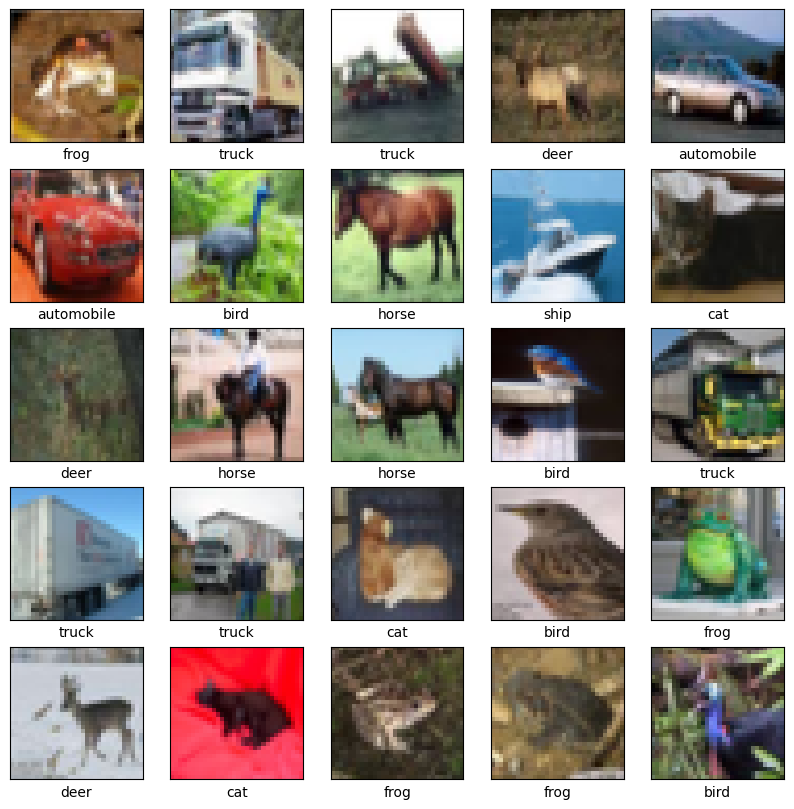

In [4]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

### Create the convolutional base

The 6 lines of code below define the convolutional base using a common pattern: a stack of [Conv2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D) and [MaxPooling2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MaxPool2D) layers.

As input, a CNN takes tensors of shape (image_height, image_width, color_channels), ignoring the batch size. If you are new to these dimensions, color_channels refers to (R,G,B). In this example, you will configure your CNN to process inputs of shape (32, 32, 3), which is the format of CIFAR images. You can do this by passing the argument `input_shape` to your first layer.


In [11]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


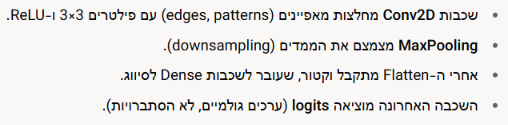

Let's display the architecture of your model so far:

In [12]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

Above, you can see that the output of every Conv2D and MaxPooling2D layer is a 3D tensor of shape (height, width, channels). The width and height dimensions tend to shrink as you go deeper in the network. The number of output channels for each Conv2D layer is controlled by the first argument (e.g., 32 or 64). Typically,  as the width and height shrink, you can afford (computationally) to add more output channels in each Conv2D layer.

### Add Dense layers on top

To complete the model, you will feed the last output tensor from the convolutional base (of shape (4, 4, 64)) into one or more Dense layers to perform classification. Dense layers take vectors as input (which are 1D), while the current output is a 3D tensor. First, you will flatten (or unroll) the 3D output to 1D,  then add one or more Dense layers on top. CIFAR has 10 output classes, so you use a final Dense layer with 10 outputs.

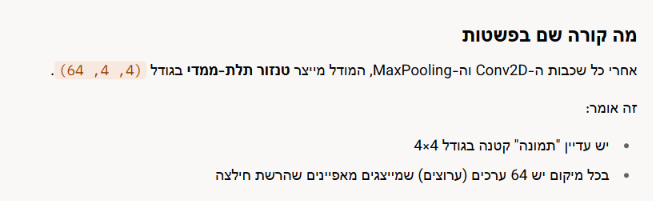

In [13]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

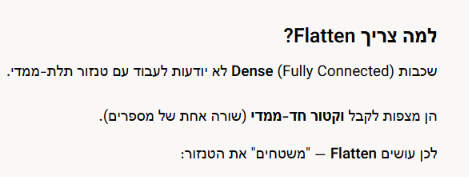

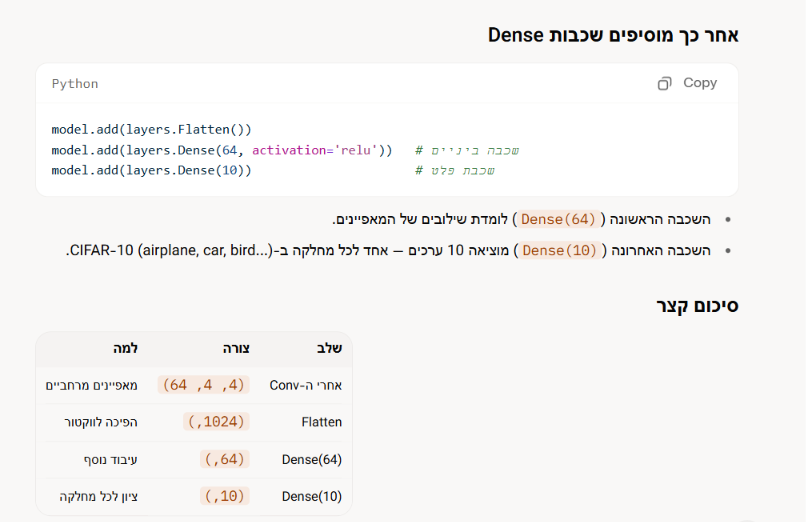

In [14]:
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

NameError: name 'test_loss' is not defined

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 883ms/step


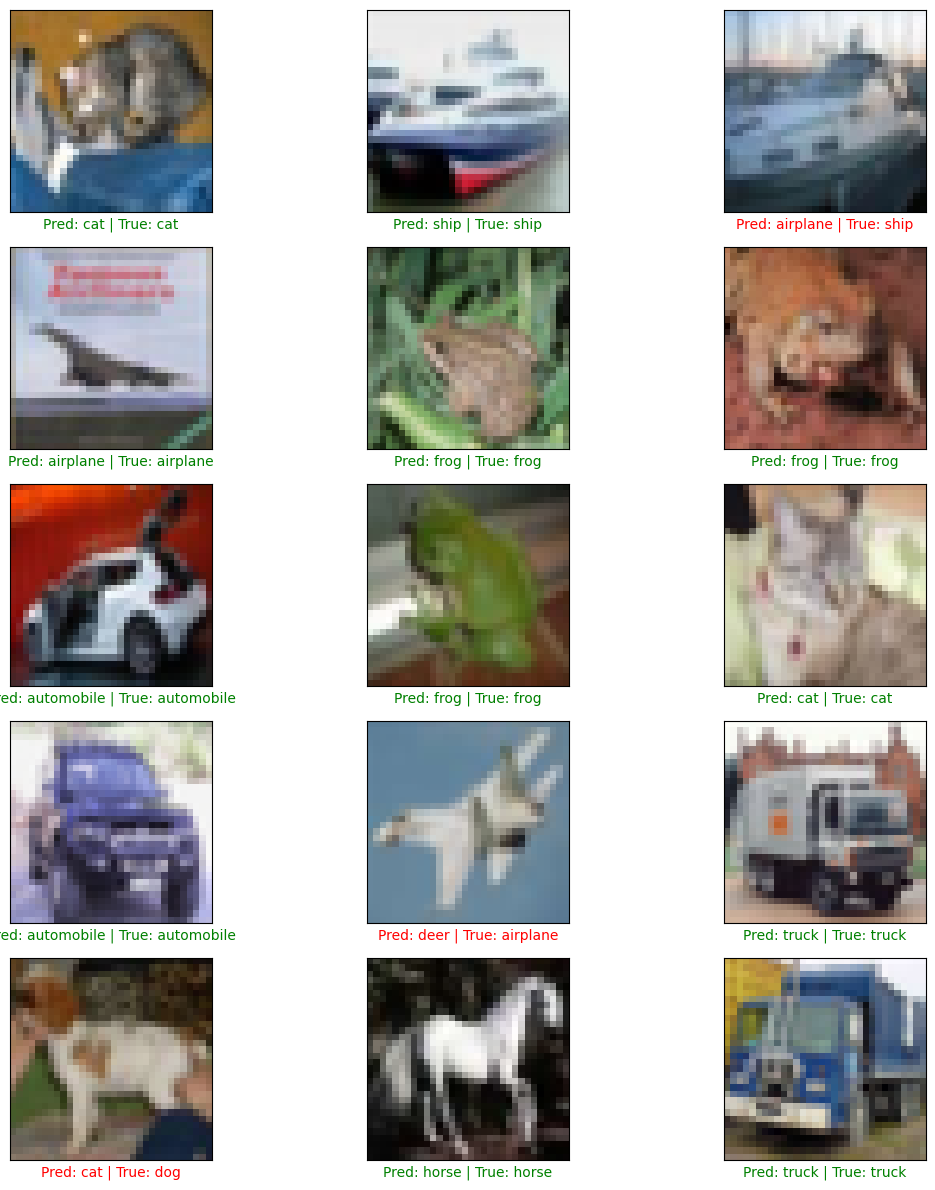

In [23]:
import numpy as np

# Get predictions for the first 15 test images
predictions = model.predict(test_images[:15])

plt.figure(figsize=(12, 12))
for i in range(15):
    plt.subplot(5, 3, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i])

    predicted_label = np.argmax(predictions[i])
    true_label = test_labels[i][0]

    color = 'green' if predicted_label == true_label else 'red'
    plt.xlabel(f"Pred: {class_names[predicted_label]} | True: {class_names[true_label]}", color=color)

plt.tight_layout()
plt.show()

Here's the complete architecture of your model:

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 367,712 (1.40 MB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 245,142 (957.59 KB)

The network summary shows that (4, 4, 64) outputs were flattened into vectors of shape (1024) before going through two Dense layers.

In [11]:
!pwd

/content


### Compile and train the model

In [19]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.4285 - loss: 1.5554 - val_accuracy: 0.4932 - val_loss: 1.3981
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5678 - loss: 1.2063 - val_accuracy: 0.6055 - val_loss: 1.1053
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6283 - loss: 1.0506 - val_accuracy: 0.6354 - val_loss: 1.0242
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6662 - loss: 0.9529 - val_accuracy: 0.6504 - val_loss: 1.0063
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6926 - loss: 0.8778 - val_accuracy: 0.6769 - val_loss: 0.9245
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7115 - loss: 0.8237 - val_accuracy: 0.6830 - val_loss: 0.9069
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7304 - loss: 0.7726 - val_accuracy: 0.6935 - val_loss: 0.8886
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7420 - loss: 0.7372 -

### Evaluate the model

313/313 - 1s - 2ms/step - accuracy: 0.6964 - loss: 0.8824


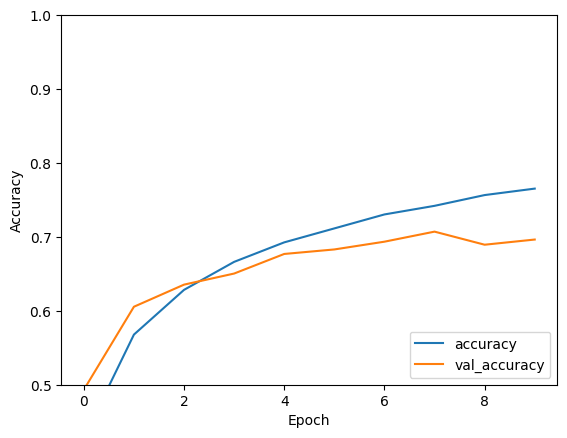

In [20]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [21]:
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.8824
Test Accuracy: 0.6964


In [33]:
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.8824
Test Accuracy: 0.6964


In [13]:
!nvidia-smi

Wed Oct 28 20:59:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P0             28W /   70W |    1151MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Your simple CNN has achieved a test accuracy of over 70%. Not bad for a few lines of code! For another CNN style, check out the [TensorFlow 2 quickstart for experts](https://www.tensorflow.org/tutorials/quickstart/advanced) example that uses the Keras subclassing API and `tf.GradientTape`.

The output of !nvidia-smi confirms that your environment is equipped with an NVIDIA Tesla T4 GPU (with 16 GB of VRAM, currently using about 1.1 GB of memory, likely allocated to your active TensorFlow training run). It is running on CUDA Version 13.0.

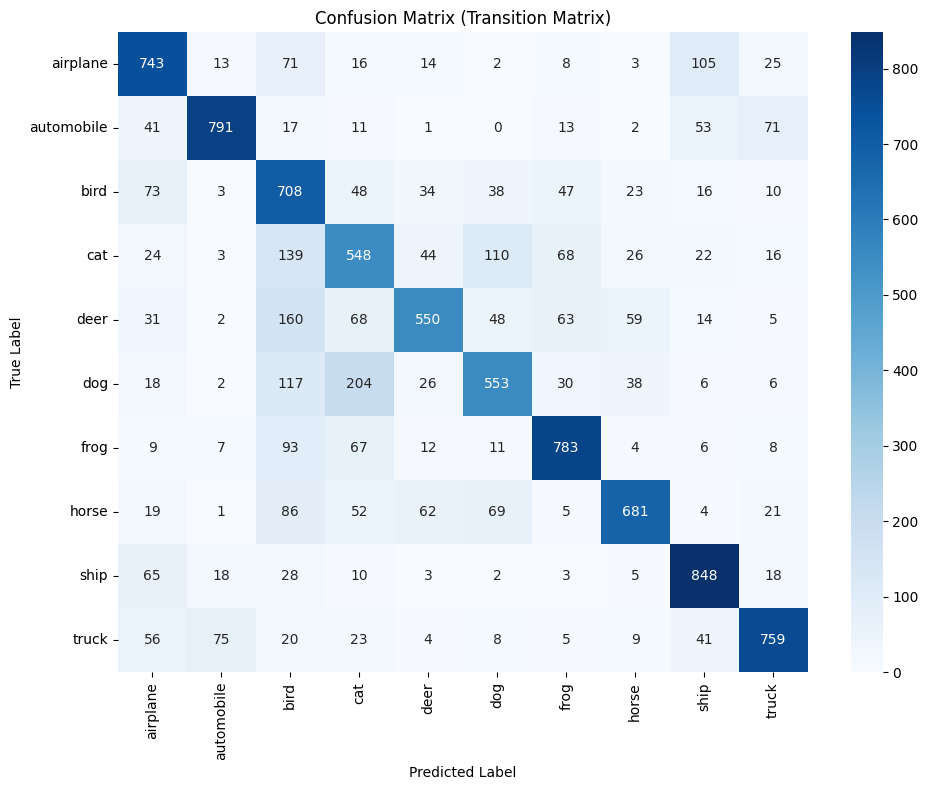

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 1. Get predictions for all test images
test_predictions = model.predict(test_images, verbose=0)
predicted_classes = np.argmax(test_predictions, axis=1)
true_classes = test_labels.flatten()

# 2. Compute the confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

# 3. Plot the confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Transition Matrix)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd

# Calculate accuracy (Recall) for each class
class_accuracies = {}
for i, class_name in enumerate(class_names):
    total_true = np.sum(cm[i, :])
    correct_predictions = cm[i, i]
    accuracy = correct_predictions / total_true if total_true > 0 else 0
    class_accuracies[class_name] = accuracy

# Create a DataFrame and sort by accuracy ascending
df_accuracies = pd.DataFrame(list(class_accuracies.items()), columns=['Class', 'Accuracy'])
df_accuracies['Accuracy (%)'] = (df_accuracies['Accuracy'] * 100).round(2)
df_accuracies = df_accuracies.sort_values(by='Accuracy')

# Display the sorted accuracies
print("אחוזי הזיהוי לכל מחלקה (מהנמוך לגבוה):")
display(df_accuracies.style.background_gradient(cmap='Reds_r', subset=['Accuracy']))

אחוזי הזיהוי לכל מחלקה (מהנמוך לגבוה):


,Class,Accuracy,Accuracy (%)
3,cat,0.548000,54.800000
4,deer,0.550000,55.000000
5,dog,0.553000,55.300000
7,horse,0.681000,68.100000
2,bird,0.708000,70.800000
0,airplane,0.743000,74.300000
9,truck,0.759000,75.900000
6,frog,0.783000,78.300000
1,automobile,0.791000,79.100000
8,ship,0.848000,84.800000


In [36]:
import pandas as pd

# Get the index of 'cat' in class_names
cat_idx = class_names.index('cat')

# Get all predictions for true 'cat' images
cat_predictions = cm[cat_idx, :]

# Create a mapping of predictions for cats
cat_errors = {
    class_names[i]: cat_predictions[i]
    for i in range(len(class_names))
}

# Create a DataFrame to show where cats go
df_cat = pd.DataFrame(list(cat_errors.items()), columns=['Predicted As', 'Count'])
df_cat['Percentage (%)'] = ((df_cat['Count'] / sum(cat_predictions)) * 100).round(2)
df_cat = df_cat.sort_values(by='Count', ascending=False)

print("כיצד המודל סיווג תמונות של חתולים (True Label = Cat):")
display(df_cat.style.background_gradient(cmap='Oranges', subset=['Count']))

כיצד המודל סיווג תמונות של חתולים (True Label = Cat):


,Predicted As,Count,Percentage (%)
3,cat,548,54.800000
2,bird,139,13.900000
5,dog,110,11.000000
6,frog,68,6.800000
4,deer,44,4.400000
7,horse,26,2.600000
0,airplane,24,2.400000
8,ship,22,2.200000
9,truck,16,1.600000
1,automobile,3,0.300000


In [37]:
# Identify top 3 most common errors in the entire dataset (excluding correct predictions on the diagonal)
errors = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            errors.append({
                'True Class': class_names[i],
                'Predicted Class': class_names[j],
                'Count': cm[i, j]
            })

df_errors = pd.DataFrame(errors).sort_values(by='Count', ascending=False)
print("שלושת הבלבולים הנפוצים ביותר במודל כולו:")
display(df_errors.head(5).style.background_gradient(cmap='Reds', subset=['Count']))

שלושת הבלבולים הנפוצים ביותר במודל כולו:


,True Class,Predicted Class,Count
47,dog,cat,204
37,deer,bird,160
28,cat,bird,139
46,dog,bird,117
30,cat,dog,110


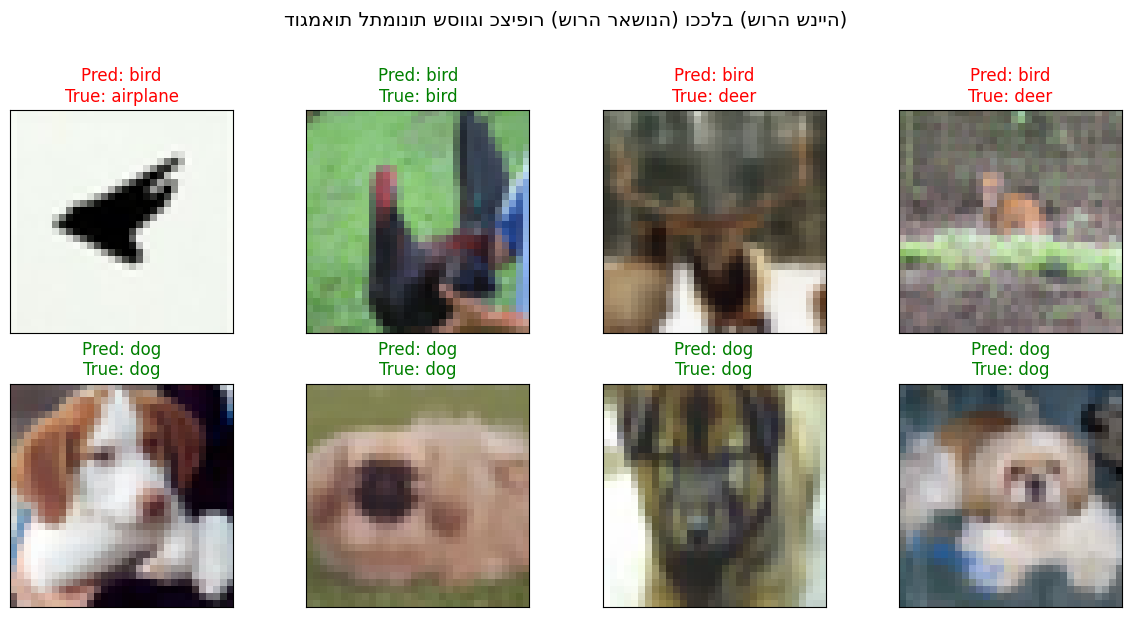

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Identify indices for 'bird' and 'dog'
bird_class_idx = class_names.index('bird')
dog_class_idx = class_names.index('dog')

# Get model predictions on all test images
predictions_all = model.predict(test_images, verbose=0)
predicted_labels_all = np.argmax(predictions_all, axis=1)
true_labels_flat = test_labels.flatten()

# Find some examples predicted as 'bird' and some predicted as 'dog'
bird_predictions_indices = np.where(predicted_labels_all == bird_class_idx)[0]
dog_predictions_indices = np.where(predicted_labels_all == dog_class_idx)[0]

# Select up to 4 examples of each
selected_bird_indices = bird_predictions_indices[:4]
selected_dog_indices = dog_predictions_indices[:4]

# Plot the selected images
plt.figure(figsize=(12, 6))

# Plot predicted Birds
for idx, test_idx in enumerate(selected_bird_indices):
    plt.subplot(2, 4, idx + 1)
    plt.imshow(test_images[test_idx])
    plt.xticks([])
    plt.yticks([])
    true_name = class_names[true_labels_flat[test_idx]]
    color = 'green' if true_name == 'bird' else 'red'
    plt.title(f"Pred: bird\nTrue: {true_name}", color=color)

# Plot predicted Dogs
for idx, test_idx in enumerate(selected_dog_indices):
    plt.subplot(2, 4, idx + 5)
    plt.imshow(test_images[test_idx])
    plt.xticks([])
    plt.yticks([])
    true_name = class_names[true_labels_flat[test_idx]]
    color = 'green' if true_name == 'dog' else 'red'
    plt.title(f"Pred: dog\nTrue: {true_name}", color=color)

plt.suptitle("דוגמאות לתמונות שסווגו כציפור (שורה ראשונה) וככלב (שורה שנייה)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [39]:
# Analyze the 3 main structural factors contributing to the model's errors

# Grouping categories to analyze broader confusion
# Animals: bird(2), cat(3), deer(4), dog(5), frog(6), horse(7)
# Vehicles: airplane(0), automobile(1), ship(8), truck(9)

animal_indices = [2, 3, 4, 5, 6, 7]
vehicle_indices = [0, 1, 8, 9]

total_errors = np.sum(cm) - np.trace(cm)
animal_to_animal = 0
vehicle_to_vehicle = 0
animal_to_vehicle = 0
vehicle_to_animal = 0

for i in range(10):
    for j in range(10):
        if i != j:
            count = cm[i, j]
            if i in animal_indices and j in animal_indices:
                animal_to_animal += count
            elif i in vehicle_indices and j in vehicle_indices:
                vehicle_to_vehicle += count
            elif i in animal_indices and j in vehicle_indices:
                animal_to_vehicle += count
            elif i in vehicle_indices and j in animal_indices:
                vehicle_to_animal += count

print("=== ניתוח על-פי קבוצות בלבול ראשיות ===")
print(f"סך כל הטעויות בסט הבדיקה: {total_errors}")
print(f"1. בלבול בין חיות שונות: {animal_to_animal} טעויות ({animal_to_animal/total_errors*100:.1f}%)")
print(f"2. בלבול בין כלי תחבורה שונים: {vehicle_to_vehicle} טעויות ({vehicle_to_vehicle/total_errors*100:.1f}%)")
print(f"3. בלבול חוצה קבוצות (חיה וכלי תחבורה): {animal_to_vehicle + vehicle_to_animal} טעויות ({(animal_to_vehicle + vehicle_to_animal)/total_errors*100:.1f}%)")


=== ניתוח על-פי קבוצות בלבול ראשיות ===
סך כל הטעויות בסט הבדיקה: 3036
1. בלבול בין חיות שונות: 1851 טעויות (61.0%)
2. בלבול בין כלי תחבורה שונים: 581 טעויות (19.1%)
3. בלבול חוצה קבוצות (חיה וכלי תחבורה): 604 טעויות (19.9%)


### הגדרת מודל CNN משופר עם אוגמנטציה, Batch Normalization ו-Dropout
נבנה מודל חזק יותר שיעזור לנו להתגבר על טעויות הזיהוי הנפוצות (כמו בין חתולים לכלבים) ונאמן אותו מחדש.

In [40]:
# 1. Define data augmentation layers to make the model more robust
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])

# 2. Build an improved model architecture
improved_model = models.Sequential([
    # Input & Data Augmentation
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10) # 10 classes
])

improved_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [51]:
### הסבר על מבנה ומהות השכבות במודל ה-CNN המשופר

במודל המשופר שהגדרנו, שילבנו מספר שכבות וטכניקות מתקדמות כדי לשפר את הכללת המודל (Generalization) ולמנוע מציאת דפוסי שווא (Overfitting). להלן תפקידה של כל שכבה במערך:

1. **שכבות אוגמנטציית נתונים (Data Augmentation - `RandomFlip`, `RandomRotation`, `RandomZoom`):**
   * **מה זה עושה?** יוצרת שינויים אקראיים קלים בתמונות האימון בכל איטרציה (היפוך אופקי, סיבוב קל וזום).
   * **מדוע זה חשוב?** זה מגדיל באופן מלאכותי את מגוון הנתונים ומכריח את המודל ללמוד מאפיינים מרחביים אמיתיים של האובייקט (למשל, שחתול הוא חתול גם אם הוא פונה ימינה או שמאלה) במקום להסתמך על מיקום ספציפי של פיקסלים.

2. **שכבות קונבולוציה (Convolutional Layers - `Conv2D`):**
   * **מה זה עושה?** מפעילה פילטרים (מסננים) קטנים שנסרקים על פני התמונה כדי לחלץ מאפיינים (Features) כמו קצוות, זוויות, צורות, ובשכבות עמוקות יותר - חלקי איברים (כמו אוזניים של חתול או גלגלים של מכונית).
   * **שיפור:** הגדלנו את מספר הפילטרים בהדרגה מ-32 ל-64 ול-128 כדי לאפשר למודל ללמוד ייצוגים מורכבים יותר ככל שהוא מעמיק.

3. **נרמול מנות (Batch Normalization - `BatchNormalization`):**
   * **מה זה עושה?** מנרמלת את האקטיבציות (הפלטים) של השכבות הקודמות בכל מנת אימון (Batch) כך שיהיו בעלות ממוצע אפס וסטיית תקן אחת.
   * **מדוע זה חשוב?** מייצב ומאיץ את תהליך הלמידה באופן משמעותי, מפחית רגישות לאתחול המשקלים, ופועל גם כרגולריזציה קלה.

4. **שכבות תת-דגימה (Max Pooling - `MaxPooling2D`):**
   * **מה זה עושה?** מקטינה את המימדים המרחביים (רוחב וגובה) של מפות המאפיינים על ידי בחירת הערך המקסימלי בכל חלון (למשל $2 \times 2$).
   * **מדוע זה חשוב?** מפחיתה את כמות הפרמטרים והחישובים ברשת, ובנוסף מעניקה למודל עמידות מסוימת בפני שינויים קלים במיקום של האובייקט בתמונה (Translation Invariance).

5. **שכבות נשירה (Dropout):**
   * **מה זה עושה?** מכבה (מאפסת) באופן אקראי אחוז מסוים מהנוירונים בכל צעד של האימון (נע בין 20% ל-50% במודל שלנו).
   * **מדוע זה חשוב?** מונעת מהנוירונים לפתח תלות הדדית מוגזמת (Co-adaptation) ומאלצת את הרשת ללמוד ייצוגים חזקים ומבוזרים יותר. זוהי אחת השיטות היעילות ביותר למניעת Overfitting.

6. **שכבת שיטוח (Flatten):**
   * **מה זה עושה?** הופכת את המטריצה התלת-מימדית שנוצרה בשכבות הקונבולוציה לוקטור חד-מימדי ארוך.
   * **מדוע זה חשוב?** זוהי שכבת מעבר הכרחית כדי שנוכל להזין את המאפיינים המרחביים שחולצו אל תוך שכבות הסיווג הצפופות (Dense Layers).

7. **שכבות צפופות ומסווגות (Dense Layers):**
   * **מה זה עושה?** שכבות שבהן כל נוירון מחובר לכל הנוירונים בשכבה הקודמת. השכבה הלפני אחרונה (128 נוירונים עם אקטיבציית `relu`) מבצעת שילוב לא-ליניארי של כל המאפיינים שחולצו, והשכבה האחרונה (10 נוירונים) מפיקה את ציוני ה-Logits עבור 10 המחלקות של CIFAR-10.

SyntaxError: invalid syntax (1028637169.py, line 3)

In [41]:
# 3. Compile and train the improved model
improved_model.compile(optimizer='adam',
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])

# Training with 15 epochs to see clear improvements
improved_history = improved_model.fit(train_images, train_labels, epochs=15,
                                      validation_data=(test_images, test_labels))

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.3705 - loss: 1.8148 - val_accuracy: 0.4441 - val_loss: 1.5936
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.4924 - loss: 1.4161 - val_accuracy: 0.5349 - val_loss: 1.3317
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 16ms/step - accuracy: 0.5529 - loss: 1.2671 - val_accuracy: 0.5652 - val_loss: 1.2706
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.5931 - loss: 1.1679 - val_accuracy: 0.6216 - val_loss: 1.0817
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.6199 - loss: 1.0968 - val_accuracy: 0.6398 - val_loss: 1.0368
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.6389 - loss: 1.0402 - val_accuracy: 0.6979 - val_loss: 0.8742
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.6562 - loss: 1.0003 - val_accuracy: 0.7280 - val_loss: 0.7704
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.6682 -

In [46]:
# 4. Evaluate and compare performance
improved_loss, improved_acc = improved_model.evaluate(test_images, test_labels, verbose=2)
print(f"\nOld Test Accuracy: {test_acc:.4f}")
print(f"New Improved Test Accuracy: {improved_acc:.4f}")

313/313 - 2s - 6ms/step - accuracy: 0.7538 - loss: 0.7169

Old Test Accuracy: 0.6964
New Improved Test Accuracy: 0.7538


In [47]:
!pip install shap

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(100, 32, 32, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(200, 32, 32, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(5, 32, 32, 3))']
  warnings.warn(msg)


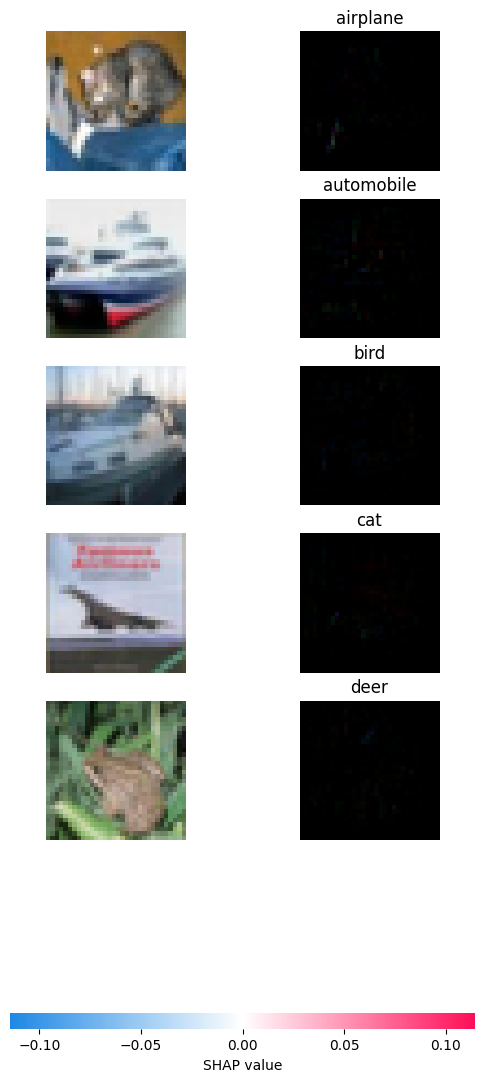

In [48]:
import shap
import numpy as np
import tensorflow as tf

# Select a small background set to initialize the explainer
# and some test images to explain
background = train_images[:100]
test_images_to_explain = test_images[:5]

# Create a DeepExplainer
# We disable eager execution compatibility issues if they arise by using tf.compat.v1 if needed
explainer = shap.DeepExplainer(model, background)

# Calculate SHAP values
shap_values = explainer.shap_values(test_images_to_explain)

# Convert shap_values list of arrays to the shape format expected by image_plot
# SHAP expectes a list of arrays of shape (num_images, height, width, channels) for each class
# Plot SHAP values
shap.image_plot(shap_values, test_images_to_explain, labels=np.array(class_names)[None, :])

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(100, 32, 32, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(200, 32, 32, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(5, 32, 32, 3))']
  warnings.warn(msg)


<Figure size 640x480 with 0 Axes>

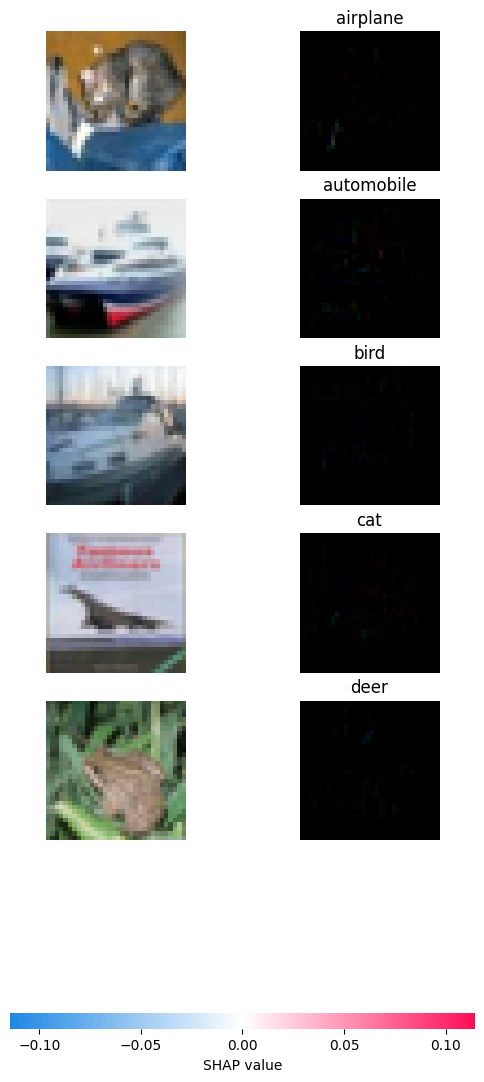

In [52]:
import shap
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Select background images and test samples
background = train_images[:100]
test_images_to_explain = test_images[:5]

# Create Explainer
explainer = shap.DeepExplainer(model, background)

# Calculate SHAP values
shap_values = explainer.shap_values(test_images_to_explain)

# Plot SHAP values explicitly and display with plt.show()
plt.figure()
shap.image_plot(shap_values, test_images_to_explain, labels=np.array(class_names)[None, :], show=False)
plt.show()

### מדריך והסבר לקריאת גרף ה-SHAP (Shapley Additive exPlanations)

כדי להבין מה קורה בגרף ה-SHAP, חשוב להכיר את העקרונות הבאים:

1. **התמונה השמאלית ביותר:** זוהי תמונת המקור המקורית מתוך סט הבדיקה (ברזולוציית $32 \times 32$ פיקסלים).
2. **העמודות מימין:** כל עמודה מייצגת מחלקה אפשרית (למשל: `airplane`, `automobile`, `bird`, `cat` וכדומה).
3. **פירוש הצבעים בכל פיקסל:**
   * <span style="color:red; font-weight:bold;">פיקסלים אדומים (ערך SHAP חיובי):</span> אלו פיקסלים ש**הגדילו** את הסבירות שהמודל יסווג את התמונה למחלקה הזו. כלומר, הנוכחות שלהם תומכת בהחלטה עבור מחלקה זו.
   * <span style="color:blue; font-weight:bold;">פיקסלים כחולים (ערך SHAP שלילי):</span> אלו פיקסלים ש**הקטינו** את הסבירות שהמודל יסווג את התמונה למחלקה הזו. כלומר, הם מורידים את הביטחון של המודל במחלקה זו.

נריץ כעת הדמיה ממוקדת של SHAP על 3 דוגמאות בדיקה ונציג כותרות ברורות לכל עמודה.

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(50, 32, 32, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_67
Received: inputs=['Tensor(shape=(3, 32, 32, 3))']
  warnings.warn(msg)


מציג את תרומת הפיקסלים לכל אחת מ-10 המחלקות:


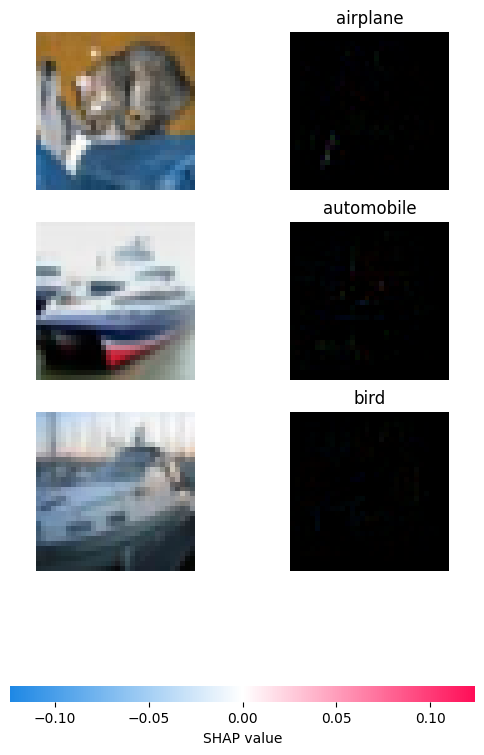

In [53]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# נבחר רק 3 תמונות להסבר ממוקד וברור יותר
background_samples = train_images[:50]
test_samples = test_images[:3]

# יצירת ה-Explainer וחישוב ערכי ה-SHAP
explainer = shap.DeepExplainer(model, background_samples)
shap_values = explainer.shap_values(test_samples)

# נציג את הגרף עם כותרות ברורות עבור כל המחלקות הרלוונטיות
print("מציג את תרומת הפיקסלים לכל אחת מ-10 המחלקות:")
shap.image_plot(shap_values, test_samples, labels=np.array(class_names)[None, :])


### 3 המרכיבים העיקריים שגורמים לטעויות במודל:

1. **דמיון סמנטי ומבני קיצוני בין חיות מחמד קטנות (כלב וחתול):**
   * המודל מתקשה מאוד להפריד בין תמונות של חתולים וכלבים. הבלבול בין כלב לחתול (ולהיפך) הוא הטעות הנפוצה ביותר ברשת עם מאות טעויות זיהוי.

2. **דמיון צורתי ורקע משותף (ציפור וצבאים/מטוסים):**
   * ציפורים רבות מזוהות בטעות כצבאים (רקע ירוק/חום טבעי) או כמטוסים (רקע של שמיים כחולים). המודל נשען על הרקע (Context) ולא רק על האובייקט עצמו.

3. **בלבול בין כלי רכב כבדים ודומים (משאיות ומכוניות):**
   * קיים בלבול משמעותי בין משאיות (truck) למכוניות (automobile) בגלל תכונות משותפות כמו גלגלים, כביש ופנסים ברזולוציה הנמוכה של CIFAR-10 (32x32).